# Chapter 1 — Coding Exercise
## Classifying Iris Species with k-Nearest Neighbors

A hands-on exercise based on **Chapter 1** of *Introduction to Machine Learning with Python* (Müller & Guido).

You will rebuild the book's first machine learning application step by step.

## What you'll practice

- Loading a built-in scikit-learn dataset
- Splitting data into **training** and **test** sets
- Building a **k-Nearest Neighbors** classifier
- Using the `fit` → `predict` → `score` workflow

**How to use this notebook:** fill in each cell marked `# TODO`, then run the **Check** cell below it. Full solutions are at the very end — try each task yourself before peeking!

> Requires `numpy` and `scikit-learn` — install with `pip install numpy scikit-learn`.

## Setup

Run this cell first to import the libraries you'll need.

In [2]:
import numpy as np
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

## Exercise 1 — Load the data

Load the built-in **Iris** dataset into a variable called `iris`.

*Hint:* `iris = load_iris()`

In [ ]:
# TODO: load the iris dataset into `iris`
iris = None  # <-- replace None with your code

In [ ]:
# Check
assert iris is not None, "Load the iris dataset into `iris` first."
print("Feature names:", list(iris.feature_names))
print("Target names :", list(iris.target_names))
print("Data shape   :", iris.data.shape)

## Exercise 2 — Explore the data

Print how many **samples** and **features** the dataset has, and how many flowers of each species are present.

*Hint:* `iris.data.shape` is `(n_samples, n_features)`; `np.bincount(iris.target)` counts each class.

In [ ]:
# TODO: print the number of samples & features, and the count of each species
# YOUR CODE HERE


## Exercise 3 — Split into training and test sets

Create `X_train, X_test, y_train, y_test` with `train_test_split`.
Pass `random_state=0` so the split is reproducible.

*Hint:* `train_test_split(iris.data, iris.target, random_state=0)`

In [ ]:
# TODO: split the data (use random_state=0)
X_train = X_test = y_train = y_test = None  # replace with your split

In [ ]:
# Check
assert X_train is not None, "Create the train/test split first."
print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)
assert len(X_train) == 112 and len(X_test) == 38, \
    "Expected a 112/38 split (random_state=0, default 75/25)."

## Exercise 4 — Build and train a classifier

Create a `KNeighborsClassifier` with `n_neighbors=1` and **fit** it on the training data. Store it in `knn`.

*Hint:* the scikit-learn pattern is `model.fit(X_train, y_train)`.

In [ ]:
# TODO: build KNeighborsClassifier(n_neighbors=1) and fit it, into `knn`
knn = None

In [ ]:
# Check
assert knn is not None, "Create and fit the model first."
print("Trained:", knn)

## Exercise 5 — Predict a new flower

A new iris has measurements `[5.0, 2.9, 1.0, 0.2]` (sepal length, sepal width, petal length, petal width).
Predict its species **name**.

*Hint:* the input must be 2-D — `np.array([[5.0, 2.9, 1.0, 0.2]])`. Map the predicted index through `iris.target_names`.

In [ ]:
X_new = np.array([[5.0, 2.9, 1.0, 0.2]])
# TODO: predict and print the species NAME of X_new
# YOUR CODE HERE


## Exercise 6 — Evaluate on the test set

Compute the model's **accuracy** on the test set and store it in `test_accuracy`.

*Hint:* `knn.score(X_test, y_test)`.

In [ ]:
# TODO: compute test-set accuracy into `test_accuracy`
test_accuracy = None

In [ ]:
# Check
assert test_accuracy is not None, "Compute test_accuracy first."
print(f"Test accuracy: {test_accuracy:.3f}")
assert test_accuracy > 0.9, "Expected > 0.90 — check your model and split."

## Exercise 7 (bonus) — Does `k` matter?

Train a k-NN for each `k` in `1..10` and print the test accuracy for each. Which value works best here?

In [ ]:
# TODO: loop over k = 1..10 and print the test accuracy for each
for k in range(1, 11):
    pass  # replace: fit KNeighborsClassifier(n_neighbors=k) and print its score

---
## Solutions

Try every exercise yourself before reading on. Run the cell below to see one correct end-to-end solution.

samples, features: (150, 4)
per-class counts : [50 50 50]


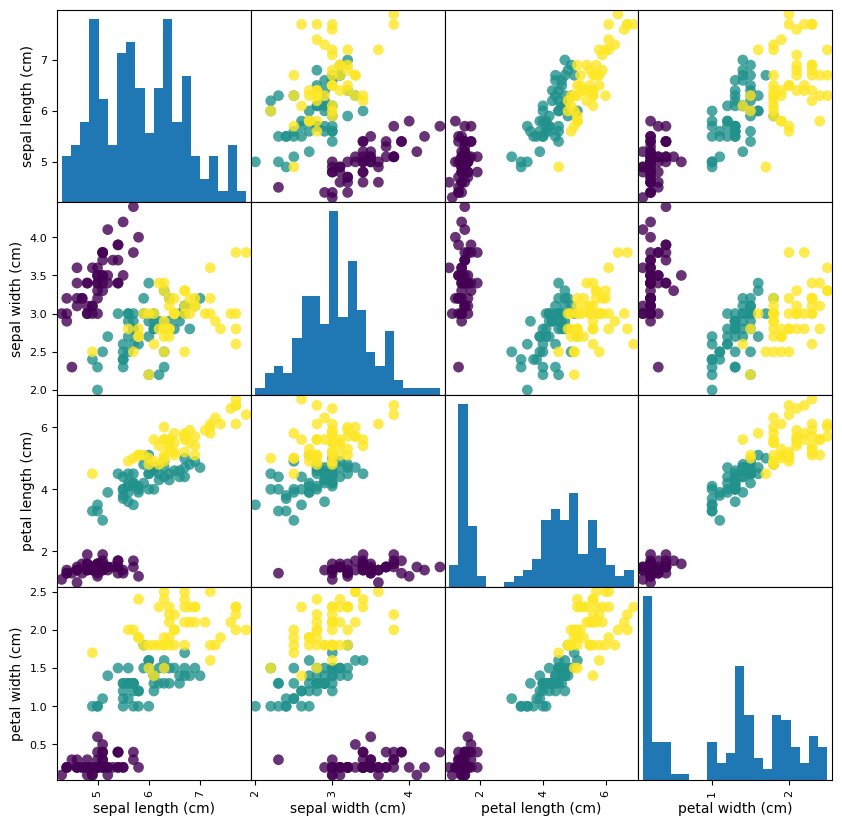

prediction: setosa
test accuracy: 0.974
k= 1  test accuracy=0.974
k= 2  test accuracy=0.974
k= 3  test accuracy=0.974
k= 4  test accuracy=0.974
k= 5  test accuracy=0.974
k= 6  test accuracy=0.974
k= 7  test accuracy=0.974
k= 8  test accuracy=0.974
k= 9  test accuracy=0.974
k=10  test accuracy=0.974


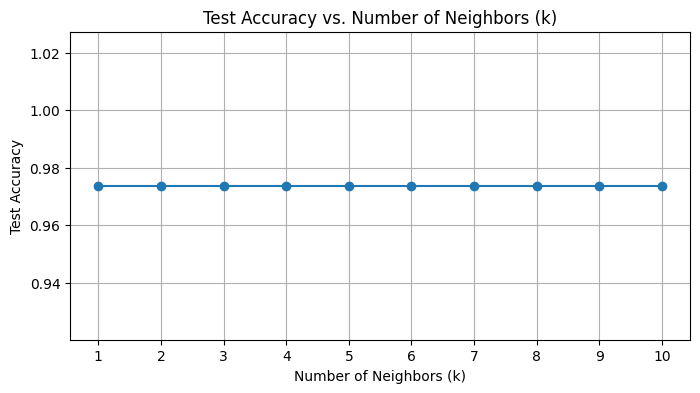

In [4]:
# Solution — full workflow
iris = load_iris()

# Exercise 2
print("samples, features:", iris.data.shape)
print("per-class counts :", np.bincount(iris.target))

# Optional. Scatter-matrix of the Iris features (optional “look at your data” step). Pair plot of the four features, coloured by species.

import matplotlib.pyplot as plt
import pandas as pd
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['species'] = pd.Categorical.from_codes(iris.target, iris.target_names)
pd.plotting.scatter_matrix(df.iloc[:, :-1], c=iris.target, figsize=(10, 10), marker='o', hist_kwds={'bins': 20}, s=60, alpha=.8)
plt.show()

# Exercise 3
X_train, X_test, y_train, y_test = train_test_split(
    iris.data, iris.target, random_state=0)

# Exercise 4
knn = KNeighborsClassifier(n_neighbors=1)
knn.fit(X_train, y_train)

# Exercise 5
X_new = np.array([[5.0, 2.9, 1.0, 0.2]])
pred = knn.predict(X_new)
print("prediction:", iris.target_names[pred][0])

# Exercise 6
print("test accuracy:", round(knn.score(X_test, y_test), 3))

# Exercise 7
for k in range(1, 11):
    m = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
    print(f"k={k:2d}  test accuracy={m.score(X_test, y_test):.3f}")


# Test accuracy as a function of the number of neighbours (optional). lot of test accuracy vs. k

plt.figure(figsize=(8, 4))
k_values = range(1, 11)
test_accuracies = [KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train).score(X_test, y_test) for k in k_values]
plt.plot(k_values, test_accuracies, marker='o')
plt.title('Test Accuracy vs. Number of Neighbors (k)')
plt.xlabel('Number of Neighbors (k)')
plt.ylabel('Test Accuracy')
plt.xticks(k_values)
plt.grid()
plt.show()